In [1]:
!pip -q install vaderSentiment gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.5 MB/s eta 0:00:00


# Predicting Kickstarter Project Success
UE24CS352A Machine Learning mini-project. Re-implementation of Khosla et al., "Crowdfunding: Predicting Kickstarter Project Success".

**Task:** binary classification (successful vs failed) using ONLY information known at launch.

**How to run:** Runtime > Run all. Upload the dataset zip when prompted. It works with the Kaggle "Kickstarter Projects" zip or a Web Robots CSV zip (the notebook detects which). The Kaggle data has no blurb, so the project title is the text field.

In [2]:
import os, re, json, ast, zipfile, subprocess, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
import joblib
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
DATA_URL = ""
DATA_PATH = ""
MAX_ROWS = 100_000
MIN_COUNT = 30
N_TOPICS = 20
RUN_TUNING = False

## 1. Load data

In [3]:
import zlib, struct, glob

KEEP = ["id", "name", "blurb", "goal", "state", "country", "currency", "deadline",
        "launched_at", "created_at", "static_usd_rate", "category", "location"]

def stream_extract(path, out):
    """Fallback for zips whose index is missing/streamed: inflate the first entry directly."""
    with open(path, "rb") as f:
        hdr = f.read(30)
        namelen, extralen = struct.unpack("<HH", hdr[26:30])
        f.read(namelen + extralen)
        d = zlib.decompressobj(-zlib.MAX_WBITS)
        with open(out, "wb") as o:
            while True:
                chunk = f.read(1 << 20)
                if not chunk:
                    break
                o.write(d.decompress(chunk))
                if d.eof:
                    break
            o.write(d.flush())
    return [out]

def get_csv_paths(path):
    with open(path, "rb") as f:
        magic = f.read(2)
    if magic != b"PK":
        return [path]
    os.makedirs("kick_csv", exist_ok=True)
    try:
        with zipfile.ZipFile(path) as z:
            z.extractall("kick_csv")
        paths = sorted(glob.glob("kick_csv/**/*.csv", recursive=True))
    except zipfile.BadZipFile:
        print("zip index unreadable, using stream extraction...")
        paths = stream_extract(path, "kick_csv/Kickstarter.csv")
    return paths

def read_csvs(paths):
    parts = []
    for p in paths:
        for chunk in pd.read_csv(p, usecols=lambda c: c in KEEP, chunksize=100_000, on_bad_lines="skip"):
            parts.append(chunk[chunk["state"].isin(["successful", "failed"])])
    return pd.concat(parts, ignore_index=True)

if DATA_URL:
    subprocess.run(["wget", "-q", "-O", "kick.zip", DATA_URL], check=True)
    path = "kick.zip"
elif DATA_PATH:
    path = DATA_PATH
else:
    from google.colab import files
    up = files.upload()
    path = list(up.keys())[0]

csv_paths = get_csv_paths(path)
csv_paths = [p for p in csv_paths if "201801" in p] or csv_paths
print("csv files:", csv_paths)

hdr = pd.read_csv(csv_paths[0], nrows=0, encoding="latin-1").columns.str.strip()
SCHEMA = "kaggle" if "main_category" in hdr else "webrobots"
print("detected dataset schema:", SCHEMA)

if SCHEMA == "kaggle":
    raw = pd.read_csv(csv_paths[0], encoding="latin-1", low_memory=False)
    raw.columns = raw.columns.str.strip()
else:
    raw = read_csvs(csv_paths)
print("rows loaded:", len(raw))

Saving Kickstarter_2026-10-12T07_08_07_724Z.zip to Kickstarter_2026-10-12T07_08_07_724Z.zip
csv files: ['kick_csv/Kickstarter.csv', 'kick_csv/Kickstarter001.csv', 'kick_csv/Kickstarter002.csv', 'kick_csv/Kickstarter003.csv', 'kick_csv/Kickstarter004.csv', 'kick_csv/Kickstarter005.csv', 'kick_csv/Kickstarter006.csv', 'kick_csv/Kickstarter007.csv', 'kick_csv/Kickstarter008.csv', 'kick_csv/Kickstarter009.csv', 'kick_csv/Kickstarter010.csv', 'kick_csv/Kickstarter011.csv', 'kick_csv/Kickstarter012.csv', 'kick_csv/Kickstarter013.csv', 'kick_csv/Kickstarter014.csv', 'kick_csv/Kickstarter015.csv', 'kick_csv/Kickstarter016.csv', 'kick_csv/Kickstarter017.csv', 'kick_csv/Kickstarter018.csv', 'kick_csv/Kickstarter019.csv', 'kick_csv/Kickstarter020.csv', 'kick_csv/Kickstarter021.csv', 'kick_csv/Kickstarter022.csv', 'kick_csv/Kickstarter023.csv', 'kick_csv/Kickstarter024.csv', 'kick_csv/Kickstarter025.csv', 'kick_csv/Kickstarter026.csv', 'kick_csv/Kickstarter027.csv', 'kick_csv/Kickstarter028.csv', 

## 2. Clean and parse
Keep only successful/failed projects, deduplicate (name, blurb, launch date, deadline) as in the paper, parse the JSON columns, convert the goal to USD, and drop everything only known after launch (backers, pledged, staff pick...).

In [4]:
def parse(s):
    if not isinstance(s, str):
        return {}
    try:
        return json.loads(s)
    except Exception:
        try:
            return ast.literal_eval(s)
        except Exception:
            return {}

raw = raw[raw["state"].isin(["successful", "failed"])].copy()

if SCHEMA == "kaggle":
    raw = raw.drop_duplicates(subset=["name", "launched", "deadline"])
    if MAX_ROWS and len(raw) > MAX_ROWS:
        raw = raw.sample(MAX_ROWS, random_state=SEED)
    raw = raw.reset_index(drop=True)
    launch = pd.to_datetime(raw["launched"], errors="coerce")
    dead = pd.to_datetime(raw["deadline"], errors="coerce")
    name = raw["name"].fillna("").astype(str)
    df = pd.DataFrame({
        "name": name,
        "text": name,                                   # no blurb in this dataset: use the project title
        "goal_usd": pd.to_numeric(raw["usd_goal_real"], errors="coerce"),
        "cat": raw["main_category"].astype(str) + "/" + raw["category"].astype(str),
        "parent": raw["main_category"].astype(str),
        "country": raw["country"].fillna("unknown").astype(str),
        "currency": raw["currency"].fillna("unknown").astype(str),
        "duration": (dead - launch).dt.total_seconds() / 86400.0,
        "launch_month": launch.dt.month,
        "launch_dow": launch.dt.dayofweek,
        "launch_year": launch.dt.year,
    })
    HAS_BLURB = False
else:
    raw = raw.drop_duplicates(subset=["name", "blurb", "launched_at", "deadline"])
    if MAX_ROWS and len(raw) > MAX_ROWS:
        raw = raw.sample(MAX_ROWS, random_state=SEED)
    raw = raw.reset_index(drop=True)
    cat = raw["category"].map(parse)
    loc = raw["location"].map(parse)
    launch = pd.to_datetime(raw["launched_at"], unit="s")
    blurb = raw["blurb"].fillna("").astype(str)
    df = pd.DataFrame({
        "name": raw["name"].fillna("").astype(str),
        "blurb": blurb,
        "text": blurb,
        "goal_usd": raw["goal"].astype(float) * raw["static_usd_rate"].fillna(1.0).astype(float),
        "cat": cat.map(lambda d: d.get("slug") or "unknown"),
        "country": raw["country"].fillna("unknown"),
        "currency": raw["currency"].fillna("unknown"),
        "city": loc.map(lambda d: d.get("name") or "unknown"),
        "loc_type": loc.map(lambda d: d.get("type") or "unknown"),
        "duration": (raw["deadline"] - raw["launched_at"]) / 86400.0,
        "prep_days": (raw["launched_at"] - raw["created_at"]) / 86400.0,
        "launch_month": launch.dt.month,
        "launch_dow": launch.dt.dayofweek,
        "launch_year": launch.dt.year,
    })
    df["parent"] = df["cat"].str.split("/").str[0]
    HAS_BLURB = True

y = (raw["state"] == "successful").astype(int).values
ok = (df["goal_usd"] > 0) & df["duration"].notna() & (df["duration"] > 0) & df["launch_year"].notna()
if "prep_days" in df.columns:
    ok &= df["prep_days"].notna()
df, y = df[ok.values].reset_index(drop=True), y[ok.values]
print(f"clean rows: {len(df)} | success rate: {y.mean():.3f} | text field = {'blurb' if HAS_BLURB else 'project name'}")
df.head()

clean rows: 69235 | success rate: 0.758 | text field = blurb


,name,blurb,text,goal_usd,cat,country,currency,city,loc_type,duration,prep_days,launch_month,launch_dow,launch_year,parent
0,Pitchshifter '99 Tour Diary (Book 3) 'No Sleep...,Book #3 in the series of limited-edition hardb...,Book #3 in the series of limited-edition hardb...,6794.927700,music/metal,GB,GBP,Nottingham,Town,30.000000,163.267523,8,5,2026,music
1,Cantrip - Fire and Wine,We're asking for help getting our new album ac...,We're asking for help getting our new album ac...,3000.000000,music/world music,US,USD,Edinburgh,Town,30.000000,6.854630,8,3,2026,music
2,East is East Provenance 15 year album re-release,"A re-edited, remixed, & remastered version of ...","A re-edited, remixed, & remastered version of ...",1200.000000,music/rock,US,USD,Concord,Town,30.000000,29.838900,8,1,2026,music
3,held album,A 10-song album for those experiencing the hea...,A 10-song album for those experiencing the hea...,8000.000000,music/faith,US,USD,Boston,Town,36.169063,3.982917,8,5,2026,music
4,LUX OBSCURA: Electric Violin Album for the Met...,"A deeply personal album about innocence, heart...","A deeply personal album about innocence, heart...",4775.985795,music/metal,GB,GBP,London,Town,30.000000,20.583171,8,5,2026,music


## 3. Quick EDA

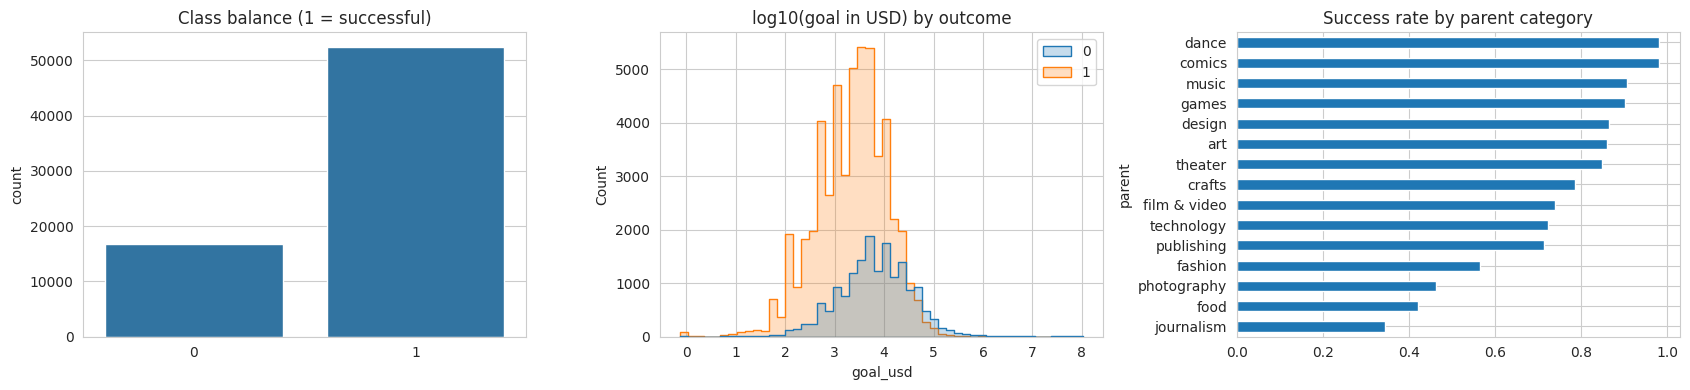

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(x=y, ax=ax[0]); ax[0].set_title("Class balance (1 = successful)")
sns.histplot(x=np.log10(df["goal_usd"]), hue=y, bins=50, ax=ax[1], element="step")
ax[1].set_title("log10(goal in USD) by outcome")
rate = pd.Series(y).groupby(df["parent"]).mean().sort_values()
rate.plot.barh(ax=ax[2]); ax[2].set_title("Success rate by parent category")
plt.tight_layout(); plt.show()

## 4. Train/test split (70/30) and feature engineering
`FeatureBuilder` creates:
- **meta**: goal, duration, prep time, launch month/weekday, name/blurb length, out-of-fold target-mean encodings of each categorical, per-level mean goal and goal-minus-mean, one-hot for category and parent category
- **nb**: out-of-fold Naive Bayes (TF-IDF) probability of success from the text field (blurb, or project title for the Kaggle data)
- **sent**: VADER sentiment of the blurb (replaces Stanford CoreNLP)
- **lda**: LDA topic probabilities of the blurb

Out-of-fold (5-fold) means a training row's encoding never uses its own label, which prevents target leakage.

In [6]:
train_df, test_df, y_train, y_test = train_test_split(
    df, y, test_size=0.3, stratify=y, random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(len(train_df), "train |", len(test_df), "test")

def clean_name(s):
    return re.sub(r"[^0-9a-zA-Z_]", "_", s)

class FeatureBuilder:
    CAT = [c for c in ["cat", "parent", "country", "currency", "city", "loc_type"] if c in df.columns]

    def __init__(self, min_count=MIN_COUNT, n_splits=5, n_topics=N_TOPICS, seed=SEED):
        self.min_count, self.n_splits, self.n_topics, self.seed = min_count, n_splits, n_topics, seed
        self.sia = SentimentIntensityAnalyzer()

    # ---------- helpers ----------
    def _group_map(self, keys, vals):
        g = pd.DataFrame({"k": keys, "v": vals}).groupby("k")["v"].agg(["mean", "count"])
        return g.loc[g["count"] >= self.min_count, "mean"]

    @staticmethod
    def _apply(keys, mp, default):
        return pd.Series(keys).map(mp).fillna(default).values

    @staticmethod
    def _make_nb():
        return make_pipeline(TfidfVectorizer(stop_words="english", min_df=5, max_df=0.35),
                             MultinomialNB())

    def _sent(self, texts):
        return np.array([self.sia.polarity_scores(t)["compound"] for t in texts])

    # ---------- build the final matrix ----------
    def _assemble(self, df, te, nb):
        out = {}
        out["log_goal"] = np.log1p(df["goal_usd"].values)
        out["goal_usd"] = df["goal_usd"].values
        out["duration"] = df["duration"].values
        if "prep_days" in df.columns:
            out["prep_days"] = df["prep_days"].values
        out["launch_month"] = df["launch_month"].values
        out["launch_dow"] = df["launch_dow"].values
        out["launch_year"] = df["launch_year"].values
        out["name_len"] = df["name"].str.len().values
        out["name_words"] = df["name"].str.split().str.len().fillna(0).values
        out["name_excl_q"] = df["name"].str.count(r"[!?]").values
        out["name_upper_ratio"] = df["name"].map(lambda s: sum(ch.isupper() for ch in s) / max(len(s), 1)).values
        if HAS_BLURB:
            out["blurb_len"] = df["blurb"].str.len().values
            out["blurb_words"] = df["blurb"].str.split().str.len().fillna(0).values
            out["blurb_excl"] = df["blurb"].str.count("!").values
        for j, c in enumerate(self.CAT):
            out[f"te_{c}"] = te[:, j]
            gm = self._apply(df[c].values, self.goal_maps_[c], self.glob_lg_)
            out[f"goalmean_{c}"] = gm
            out[f"goaldiff_{c}"] = out["log_goal"] - gm
        for c in ["cat", "parent"]:
            cats = pd.Categorical(df[c], categories=self.levels_[c])
            oh = pd.get_dummies(cats).values.astype(np.float32)
            for i, lvl in enumerate(self.levels_[c]):
                out[f"oh_{c}_{clean_name(str(lvl))}"] = oh[:, i]
        meta_cols = list(out.keys())
        out["nb_prob"] = nb
        out["sentiment"] = self._sent(df["text"].values)
        topics = self.lda_.transform(self.cv_.transform(df["text"].values))
        for i in range(self.n_topics):
            out[f"lda_{i}"] = topics[:, i]
        X = pd.DataFrame(out).astype(np.float32)
        self.groups_ = {
            "meta": meta_cols,
            "nb": ["nb_prob"],
            "sent": ["sentiment"],
            "lda": [f"lda_{i}" for i in range(self.n_topics)],
        }
        return X

    # ---------- fit on train (out-of-fold encodings) ----------
    def fit_transform(self, df, y):
        self.prior_ = y.mean()
        self.te_maps_ = {c: self._group_map(df[c].values, y) for c in self.CAT}
        lg = np.log1p(df["goal_usd"].values)
        self.glob_lg_ = lg.mean()
        self.goal_maps_ = {c: self._group_map(df[c].values, lg) for c in self.CAT}
        self.levels_ = {c: df[c].value_counts().index.tolist() for c in ["cat", "parent"]}

        te = np.zeros((len(df), len(self.CAT)))
        nb = np.zeros(len(df))
        kf = KFold(self.n_splits, shuffle=True, random_state=self.seed)
        for tr, va in kf.split(df):
            ytr = y[tr]
            prior = ytr.mean()
            for j, c in enumerate(self.CAT):
                mp = self._group_map(df[c].values[tr], ytr)
                te[va, j] = self._apply(df[c].values[va], mp, prior)
            nb_model = self._make_nb().fit(df["text"].values[tr], ytr)
            nb[va] = nb_model.predict_proba(df["text"].values[va])[:, 1]

        self.nb_ = self._make_nb().fit(df["text"].values, y)
        self.cv_ = CountVectorizer(stop_words="english", min_df=5, max_df=0.35, max_features=5000)
        counts = self.cv_.fit_transform(df["text"].values)
        self.lda_ = LatentDirichletAllocation(n_components=self.n_topics, learning_method="online",
                                              max_iter=5, random_state=self.seed, n_jobs=-1).fit(counts)
        return self._assemble(df, te, nb)

    # ---------- apply to new data ----------
    def transform(self, df):
        te = np.column_stack([self._apply(df[c].values, self.te_maps_[c], self.prior_)
                              for c in self.CAT])
        nb = self.nb_.predict_proba(df["text"].values)[:, 1]
        return self._assemble(df, te, nb)

t0 = time.time()
fb = FeatureBuilder()
X_train = fb.fit_transform(train_df, y_train)
X_test = fb.transform(test_df)[X_train.columns]
print(f"features: {X_train.shape[1]} | built in {time.time()-t0:.0f}s")
for g, cols in fb.groups_.items():
    print(f"  {g}: {len(cols)} features")

48464 train | 20771 test
features: 241 | built in 123s
  meta: 219 features
  nb: 1 features
  sent: 1 features
  lda: 20 features


## 5. Train and compare all models
Class weighting is used where supported. Linear models, SVM and MLP use standardized inputs. OLS/Ridge/Lasso are regressions thresholded at 0.5, as in the paper.

In [7]:
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
sw = compute_sample_weight("balanced", y_train)

SPECS = {
    "OLS":            dict(m=LinearRegression(), scale=True, reg=True),
    "Ridge":          dict(m=Ridge(alpha=10), scale=True, reg=True),
    "Lasso":          dict(m=Lasso(alpha=1e-3), scale=True, reg=True),
    "Logistic":       dict(m=LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000), scale=True, reg=False),
    "SVM (LinearSVC)": dict(m=LinearSVC(C=1.0, dual=False, class_weight="balanced"), scale=True, reg=False),
    "Neural Net":     dict(m=MLPClassifier(hidden_layer_sizes=(64,), early_stopping=True, batch_size=256,
                                           max_iter=50, random_state=SEED), scale=True, reg=False),
    "R. Forest":      dict(m=RandomForestClassifier(n_estimators=200, max_depth=30, min_samples_leaf=10,
                                                    max_features="sqrt", class_weight="balanced",
                                                    n_jobs=-1, random_state=SEED), scale=False, reg=False),
    "G. Boosting (LightGBM)": dict(m=lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                                                       subsample=0.75, subsample_freq=1, colsample_bytree=0.4,
                                                       class_weight="balanced", random_state=SEED, n_jobs=-1,
                                                       verbose=-1), scale=False, reg=False),
}

def metrics(yt, yp):
    p, r, _, _ = precision_recall_fscore_support(yt, yp, labels=[0, 1], zero_division=0)
    return {"A": accuracy_score(yt, yp), "F1": f1_score(yt, yp), "P1": p[1], "P0": p[0], "R1": r[1], "R0": r[0]}

rows, fitted = [], {}
for name, s in SPECS.items():
    t = time.time()
    Xa, Xb = (Xtr_s, Xte_s) if s["scale"] else (X_train.values, X_test.values)
    m = s["m"]
    if s["reg"]:
        m.fit(Xa, y_train, sample_weight=sw)
        pred = (m.predict(Xb) > 0.5).astype(int)
    else:
        m.fit(Xa, y_train)
        pred = m.predict(Xb)
    fitted[name] = m
    rows.append({"Model": name, **metrics(y_test, pred), "sec": round(time.time() - t, 1)})
    print(f"{name:25s} acc={rows[-1]['A']:.3f}  f1={rows[-1]['F1']:.3f}  ({rows[-1]['sec']}s)")

results = pd.DataFrame(rows).sort_values("A", ascending=False).reset_index(drop=True)
results.round(3)

OLS                       acc=0.823  f1=0.874  (0.6s)
Ridge                     acc=0.824  f1=0.875  (0.2s)
Lasso                     acc=0.827  f1=0.877  (3.2s)
Logistic                  acc=0.831  f1=0.881  (2.8s)
SVM (LinearSVC)           acc=0.828  f1=0.878  (13.1s)
Neural Net                acc=0.864  f1=0.911  (11.2s)
R. Forest                 acc=0.852  f1=0.898  (28.8s)
G. Boosting (LightGBM)    acc=0.864  f1=0.906  (11.0s)


,Model,A,F1,P1,P0,R1,R0,sec
0,G. Boosting (LightGBM),0.864,0.906,0.943,0.677,0.873,0.836,11.0
1,Neural Net,0.864,0.911,0.902,0.733,0.920,0.688,11.2
2,R. Forest,0.852,0.898,0.939,0.655,0.861,0.824,28.8
3,Logistic,0.831,0.881,0.949,0.607,0.822,0.861,2.8
4,SVM (LinearSVC),0.828,0.878,0.948,0.602,0.818,0.860,13.1
5,Lasso,0.827,0.877,0.946,0.600,0.818,0.854,3.2
6,Ridge,0.824,0.875,0.947,0.595,0.813,0.858,0.2
7,OLS,0.823,0.874,0.947,0.594,0.812,0.858,0.6


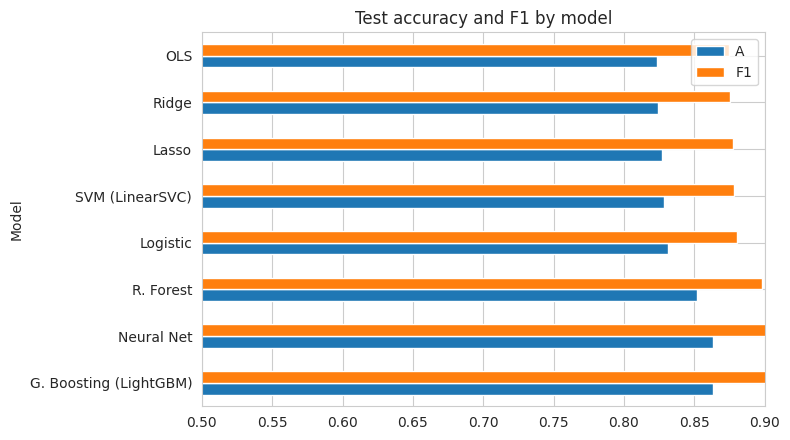

In [8]:
ax = results.set_index("Model")[["A", "F1"]].plot.barh(figsize=(8, 4.5))
ax.set_xlim(0.5, 0.9); ax.set_title("Test accuracy and F1 by model"); plt.tight_layout(); plt.show()

## 6. Optional: hyperparameter search for gradient boosting
Set `RUN_TUNING = True` in the config cell and re-run this cell if you want a tuning step for the report.

In [9]:
best_name = "G. Boosting (LightGBM)"
if RUN_TUNING:
    from sklearn.model_selection import RandomizedSearchCV
    grid = {"num_leaves": [31, 63, 127, 255], "learning_rate": [0.03, 0.05, 0.1],
            "n_estimators": [300, 500, 800], "colsample_bytree": [0.3, 0.5, 0.8],
            "min_child_samples": [20, 50, 100]}
    rs = RandomizedSearchCV(lgb.LGBMClassifier(subsample=0.75, subsample_freq=1, class_weight="balanced",
                                               random_state=SEED, n_jobs=-1, verbose=-1),
                            grid, n_iter=8, cv=3, scoring="accuracy", random_state=SEED, n_jobs=1)
    rs.fit(X_train, y_train)
    print("best params:", rs.best_params_, "| cv acc:", round(rs.best_score_, 4))
    fitted[best_name] = rs.best_estimator_
    print("test acc:", round(accuracy_score(y_test, rs.best_estimator_.predict(X_test)), 4))
else:
    print("Skipped (RUN_TUNING = False)")

Skipped (RUN_TUNING = False)


## 7. Error analysis for the best model

              precision    recall  f1-score   support

      failed      0.677     0.836     0.748      5036
  successful      0.943     0.873     0.906     15735

    accuracy                          0.864     20771
   macro avg      0.810     0.854     0.827     20771
weighted avg      0.879     0.864     0.868     20771



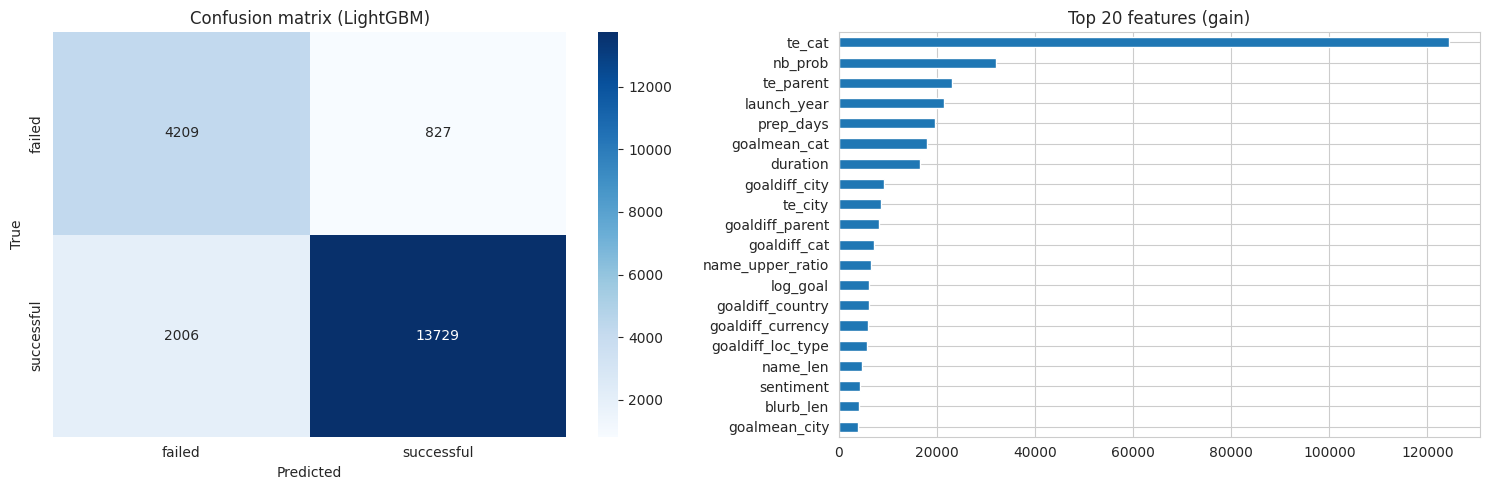

In [10]:
best_model = fitted[best_name]
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["failed", "successful"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["failed", "successful"], yticklabels=["failed", "successful"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title("Confusion matrix (LightGBM)")
imp = pd.Series(best_model.booster_.feature_importance("gain"), index=X_train.columns).nlargest(20)
imp[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Top 20 features (gain)")
plt.tight_layout(); plt.show()

## 8. Ablation: does the text help? (mirrors the paper's 5 samples)

In [11]:
G = fb.groups_
samples = {
    "Metadata": G["meta"],
    "Metadata + NB": G["meta"] + G["nb"],
    "Metadata + NB + Sentiment": G["meta"] + G["nb"] + G["sent"],
    "Metadata + NB + LDA": G["meta"] + G["nb"] + G["lda"],
    "All features": G["meta"] + G["nb"] + G["sent"] + G["lda"],
}
abl = []
for label, cols in samples.items():
    accs, f1s = [], []
    for seed in [1, 2, 3]:
        m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.75,
                               subsample_freq=1, colsample_bytree=0.4, class_weight="balanced",
                               random_state=seed, n_jobs=-1, verbose=-1).fit(X_train[cols], y_train)
        p = m.predict(X_test[cols])
        accs.append(accuracy_score(y_test, p)); f1s.append(f1_score(y_test, p))
    abl.append({"Sample": label, "n_features": len(cols), "Acc": np.mean(accs), "F1": np.mean(f1s)})
abl = pd.DataFrame(abl)
display(abl.round(4)) if "display" in globals() else print(abl.round(4))

                      Sample  n_features     Acc      F1
0                   Metadata         219  0.8572  0.9015
1              Metadata + NB         220  0.8612  0.9044
2  Metadata + NB + Sentiment         221  0.8621  0.9051
3        Metadata + NB + LDA         240  0.8632  0.9061
4               All features         241  0.8641  0.9067


## 9. Save artifacts and build the live demo
The cell below saves the trained pipeline, then launches a Gradio app with a public link for the review.

In [12]:
final_model = fitted[best_name]
feature_cols = list(X_train.columns)
joblib.dump({"fb": fb, "model": final_model, "cols": feature_cols}, "kickstarter_model.joblib")
print("saved kickstarter_model.joblib")

saved kickstarter_model.joblib


In [13]:
cat_choices = sorted(df["cat"].unique())
country_choices = sorted(df["country"].unique())
cat2parent = df.drop_duplicates("cat").set_index("cat")["parent"].to_dict()
country2cur = df.groupby("country")["currency"].agg(lambda s: s.mode().iloc[0]).to_dict()
HAS_CITY = "city" in df.columns
if HAS_CITY:
    city2type = df.drop_duplicates("city").set_index("city")["loc_type"].to_dict()

def predict_project(name, blurb, goal_usd, category, country, city, duration, prep_days, month, weekday, year):
    name = name or ""
    r = {
        "name": name, "text": (blurb or "") if HAS_BLURB else name,
        "goal_usd": float(max(goal_usd, 1)),
        "cat": category, "parent": cat2parent.get(category, "unknown"),
        "country": country, "currency": country2cur.get(country, "unknown"),
        "duration": float(duration),
        "launch_month": int(month), "launch_dow": int(weekday), "launch_year": int(year),
    }
    if HAS_BLURB:
        r["blurb"] = blurb or ""
    if HAS_CITY:
        c = (city or "").strip() or "unknown"
        r["city"], r["loc_type"] = c, city2type.get(c, "unknown")
    if "prep_days" in df.columns:
        r["prep_days"] = float(prep_days)
    p = float(final_model.predict_proba(fb.transform(pd.DataFrame([r]))[feature_cols])[0, 1])
    return {"Successful": p, "Failed": 1 - p}

print(predict_project("Test game", "A cooperative card game", 5000, cat_choices[0],
                      country_choices[0], "", 30, 14, 3, 1, 2017))

{'Successful': 0.9684741163444573, 'Failed': 0.03152588365554265}


In [14]:
import gradio as gr
inputs = [
    gr.Textbox(label="Project name (title)"),
    gr.Textbox(label="Blurb (only used if the dataset has one)", lines=2),
    gr.Number(label="Funding goal (USD)", value=10000),
    gr.Dropdown(cat_choices, label="Category", value=cat_choices[0]),
    gr.Dropdown(country_choices, label="Country", value="US" if "US" in country_choices else country_choices[0]),
    gr.Textbox(label="Creator city (only used if the dataset has one)"),
    gr.Slider(1, 90, value=30, step=1, label="Campaign duration (days)"),
    gr.Slider(0, 365, value=14, step=1, label="Days between creation and launch (only if available)"),
    gr.Slider(1, 12, value=3, step=1, label="Launch month"),
    gr.Slider(0, 6, value=1, step=1, label="Launch weekday (0 = Monday)"),
    gr.Slider(2009, 2026, value=int(df["launch_year"].max()), step=1, label="Launch year"),
]
demo = gr.Interface(fn=predict_project, inputs=inputs,
                    outputs=gr.Label(num_top_classes=2, label="Predicted outcome"),
                    title="Kickstarter Success Predictor",
                    description="Enter launch-time information to estimate the chance of reaching the goal.")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://991f25e49b7d384284.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
